In [1]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import gc
import math
import random
import warnings
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import (
    Adam,
    RMSprop,
    SGD
)

warnings.filterwarnings("ignore")




ModuleNotFoundError: No module named 'tensorflow'

In [ ]:
# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

np.random.seed(SEED)

random.seed(SEED)

tf.random.set_seed(SEED)


print("=" * 60)

print("TensorFlow Version:", tf.__version__)

print("=" * 60)

TensorFlow Version: 2.20.0


In [ ]:
# ============================================================
# 3. FIND train.csv AUTOMATICALLY
# ============================================================

import os

train_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "train.csv":
            train_files.append(
                os.path.join(root, file)
            )

print("Found train.csv files:\n")

for path in train_files:
    print(path)

if len(train_files) == 0:
    raise FileNotFoundError(
        "train.csv was not found inside /kaggle/input. "
        "Please add the NYC Taxi dataset using "
        "Kaggle → Add Input."
    )

DATA_PATH = train_files[0]

print("\nUsing dataset:")
print(DATA_PATH)



Found train.csv files:

/kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv

Using dataset:
/kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv


In [ ]:
# ============================================================
# 4. LOAD DATASET
# ============================================================

N_ROWS = 100000

print("\nLoading dataset...")

df = pd.read_csv(
    DATA_PATH,
    nrows=N_ROWS
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)


Loading dataset...
Dataset loaded successfully.
Dataset shape: (100000, 8)


In [ ]:
# ============================================================
# 7. DATASET UNDERSTANDING
# ============================================================

print("\n" + "=" * 60)

print("DATASET UNDERSTANDING")

print("=" * 60)


print("\nFirst 5 rows:")

display(
    df.head()
)


print("\nLast 5 rows:")

display(
    df.tail()
)


print("\nDataset shape:")

print(
    df.shape
)


print("\nColumn names:")

print(
    df.columns.tolist()
)


print("\nDataset information:")

df.info()


print("\nDescriptive statistics:")

display(
    df.describe()
)



DATASET UNDERSTANDING

First 5 rows:


,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2009-06-15 17:26:21.0000001,4.5,2009-06-15 17:26:21 UTC,-73.844311,40.721319,-73.841610,40.712278,1
1,2010-01-05 16:52:16.0000002,16.9,2010-01-05 16:52:16 UTC,-74.016048,40.711303,-73.979268,40.782004,1
2,2011-08-18 00:35:00.00000049,5.7,2011-08-18 00:35:00 UTC,-73.982738,40.761270,-73.991242,40.750562,2
3,2012-04-21 04:30:42.0000001,7.7,2012-04-21 04:30:42 UTC,-73.987130,40.733143,-73.991567,40.758092,1
4,2010-03-09 07:51:00.000000135,5.3,2010-03-09 07:51:00 UTC,-73.968095,40.768008,-73.956655,40.783762,1



Last 5 rows:


,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
99995,2013-09-24 07:39:00.00000071,9.0,2013-09-24 07:39:00 UTC,-73.947977,40.784792,-73.964262,40.792347,5
99996,2014-05-15 12:15:45.0000001,6.0,2014-05-15 12:15:45 UTC,-73.962918,40.799107,-73.974178,40.786487,1
99997,2015-02-19 17:40:43.0000001,5.0,2015-02-19 17:40:43 UTC,-73.996773,40.723549,-73.991974,40.724724,1
99998,2009-10-10 23:35:00.000000165,6.9,2009-10-10 23:35:00 UTC,-73.983652,40.756667,-73.982715,40.767067,4
99999,2010-11-09 16:09:00.00000015,5.7,2010-11-09 16:09:00 UTC,-73.975663,40.791653,-73.982267,40.774968,1



Dataset shape:
(100000, 8)

Column names:
['key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   key                100000 non-null  object 
 1   fare_amount        100000 non-null  float64
 2   pickup_datetime    100000 non-null  object 
 3   pickup_longitude   100000 non-null  float64
 4   pickup_latitude    100000 non-null  float64
 5   dropoff_longitude  100000 non-null  float64
 6   dropoff_latitude   100000 non-null  float64
 7   passenger_count    100000 non-null  int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 6.1+ MB

Descriptive statistics:


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,11.354652,-72.494682,39.914481,-72.490967,39.919053,1.673820
std,9.716777,10.693934,6.225686,10.471386,6.213427,1.300171
min,-44.900000,-736.550000,-74.007670,-84.654241,-74.006377,0.000000
25%,6.000000,-73.992041,40.734996,-73.991215,40.734182,1.000000
50%,8.500000,-73.981789,40.752765,-73.980000,40.753243,1.000000
75%,12.500000,-73.966982,40.767258,-73.963433,40.768166,2.000000
max,200.000000,40.787575,401.083332,40.851027,404.616667,6.000000


In [ ]:
# ============================================================
# 8. TARGET VARIABLE
# ============================================================

TARGET = "fare_amount"


print("\n" + "=" * 60)

print("TARGET VARIABLE")

print("=" * 60)


print(
    "Target:",
    TARGET
)


print("\nTarget statistics:")

display(
    df[TARGET].describe()
)



TARGET VARIABLE
Target: fare_amount

Target statistics:


count    100000.000000
mean         11.354652
std           9.716777
min         -44.900000
25%           6.000000
50%           8.500000
75%          12.500000
max         200.000000
Name: fare_amount, dtype: float64


MISSING VALUE ANALYSIS


,Missing Values,Percentage
key,0,0.0
fare_amount,0,0.0
pickup_datetime,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,0,0.0
dropoff_latitude,0,0.0
passenger_count,0,0.0


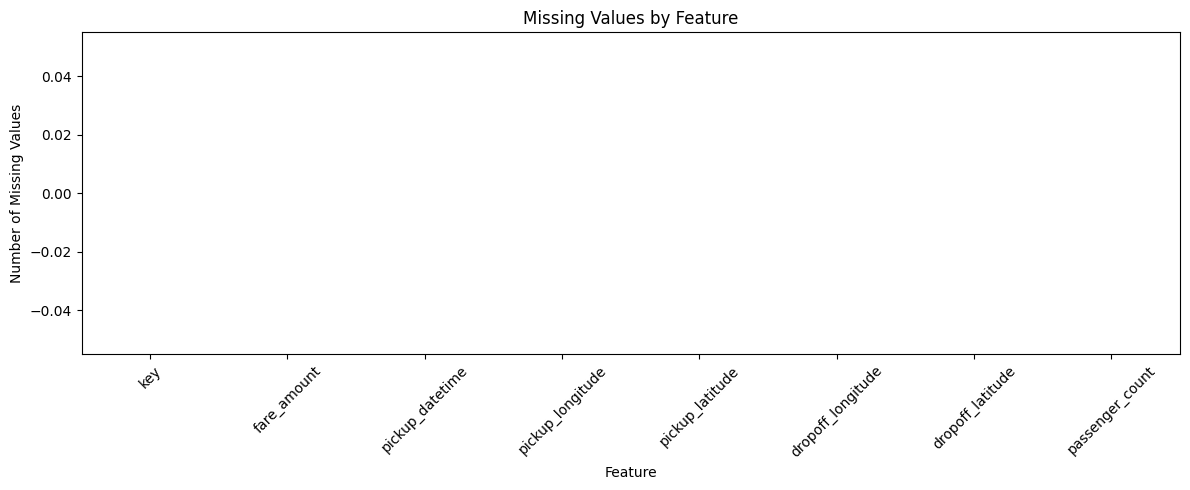

In [ ]:
# ============================================================
# 9. MISSING VALUE ANALYSIS
# ============================================================

print("\n" + "=" * 60)

print("MISSING VALUE ANALYSIS")

print("=" * 60)


missing = (
    df.isnull().sum()
)


missing_percentage = (

    df.isnull().sum()

    /

    len(df)

    *

    100
)


missing_table = pd.DataFrame({

    "Missing Values":
        missing,

    "Percentage":
        missing_percentage
})


display(
    missing_table
)


# Missing value visualization

plt.figure(
    figsize=(12, 5)
)


sns.barplot(

    x=missing.index,

    y=missing.values
)


plt.title(
    "Missing Values by Feature"
)


plt.xlabel(
    "Feature"
)


plt.ylabel(
    "Number of Missing Values"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 10. DUPLICATE ANALYSIS
# ============================================================

print("\n" + "=" * 60)

print("DUPLICATE ANALYSIS")

print("=" * 60)


duplicate_count = (
    df.duplicated().sum()
)


print(
    "Number of duplicate rows:",
    duplicate_count
)


df = df.drop_duplicates()


print(
    "Shape after removing duplicates:",
    df.shape
)


DUPLICATE ANALYSIS
Number of duplicate rows: 0
Shape after removing duplicates: (100000, 8)



FARE ANALYSIS


count    100000.000000
mean         11.354652
std           9.716777
min         -44.900000
25%           6.000000
50%           8.500000
75%          12.500000
max         200.000000
Name: fare_amount, dtype: float64

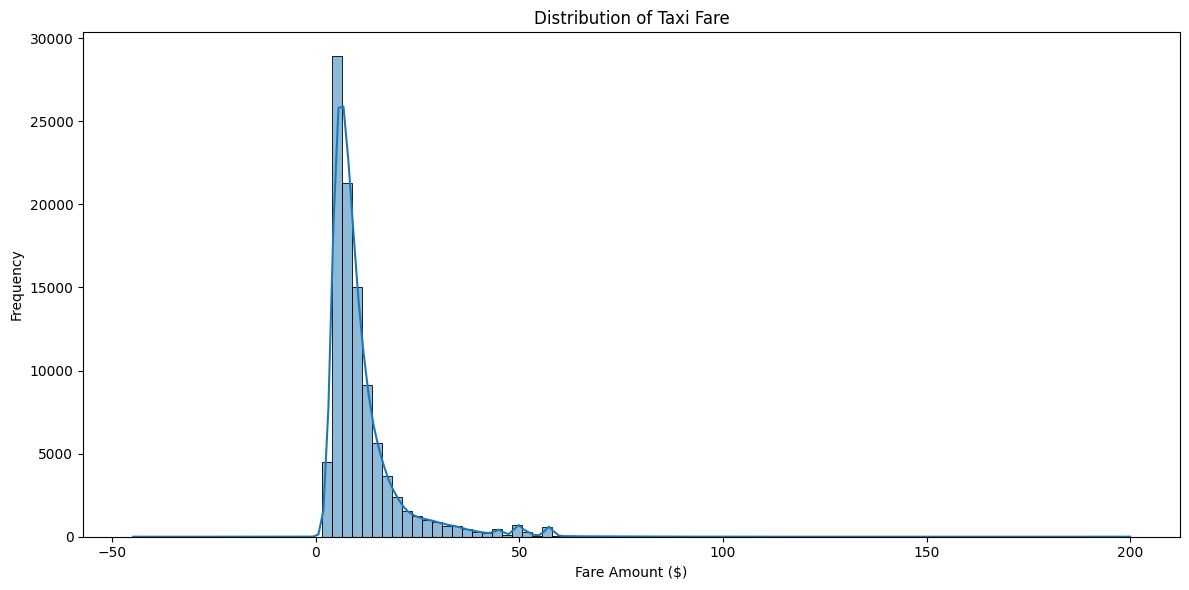

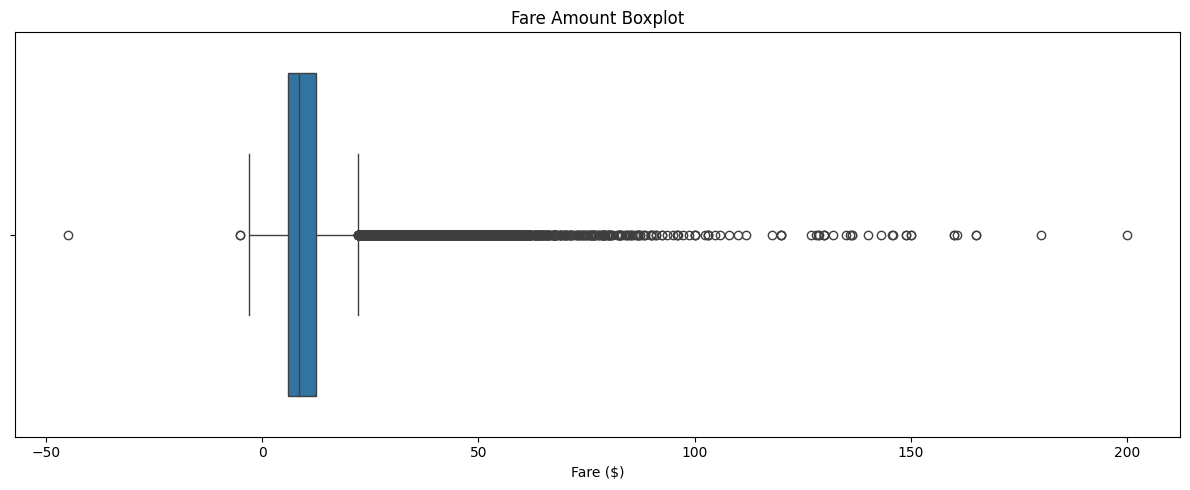

In [ ]:
# ============================================================
# 11. FARE DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)

print("FARE ANALYSIS")

print("=" * 60)


display(
    df[TARGET].describe()
)


# Histogram

plt.figure(
    figsize=(12, 6)
)


sns.histplot(

    df[TARGET],

    bins=100,

    kde=True
)


plt.title(
    "Distribution of Taxi Fare"
)


plt.xlabel(
    "Fare Amount ($)"
)


plt.ylabel(
    "Frequency"
)


plt.tight_layout()

plt.show()


# Boxplot

plt.figure(
    figsize=(12, 5)
)


sns.boxplot(
    x=df[TARGET]
)


plt.title(
    "Fare Amount Boxplot"
)


plt.xlabel(
    "Fare ($)"
)


plt.tight_layout()

plt.show()



PASSENGER COUNT ANALYSIS


passenger_count
0      366
1    69619
2    14561
3     4289
4     2091
5     7034
6     2040
Name: count, dtype: int64

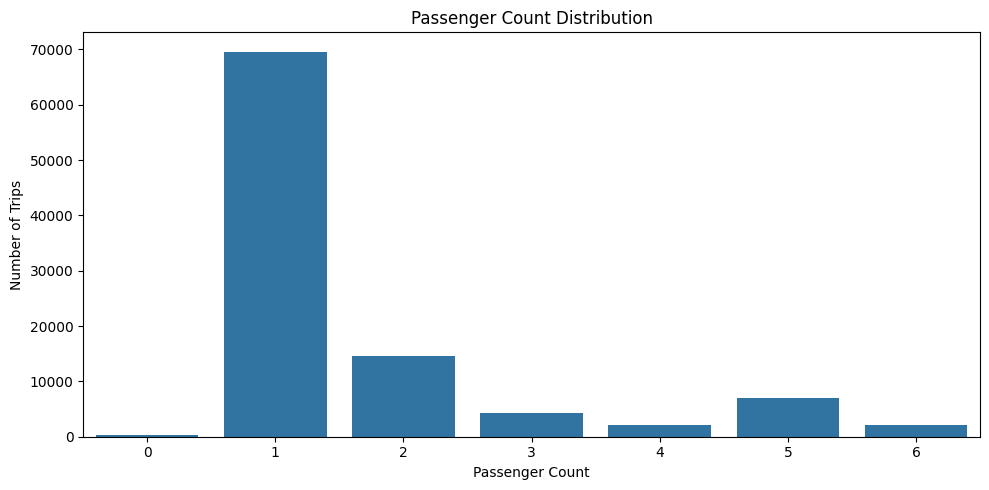

In [ ]:
# ============================================================
# 12. PASSENGER COUNT ANALYSIS
# ============================================================

print("\n" + "=" * 60)

print("PASSENGER COUNT ANALYSIS")

print("=" * 60)


display(

    df[
        "passenger_count"
    ]
    .value_counts()
    .sort_index()
)


plt.figure(
    figsize=(10, 5)
)


sns.countplot(

    x="passenger_count",

    data=df
)


plt.title(
    "Passenger Count Distribution"
)


plt.xlabel(
    "Passenger Count"
)


plt.ylabel(
    "Number of Trips"
)


plt.tight_layout()

plt.show()


In [ ]:
# ============================================================
# 13. DATETIME CONVERSION
# ============================================================

print("\n" + "=" * 60)

print("DATETIME PROCESSING")

print("=" * 60)


df["pickup_datetime"] = pd.to_datetime(

    df["pickup_datetime"],

    errors="coerce"
)


print(
    df[
        ["pickup_datetime"]
    ].head()
)


print(
    "\nInvalid datetime values:",

    df[
        "pickup_datetime"
    ]
    .isnull()
    .sum()
)


# Remove invalid datetime rows

df = df.dropna(

    subset=[
        "pickup_datetime"
    ]
)


print(
    "Shape after datetime cleaning:",
    df.shape
)



DATETIME PROCESSING
            pickup_datetime
0 2009-06-15 17:26:21+00:00
1 2010-01-05 16:52:16+00:00
2 2011-08-18 00:35:00+00:00
3 2012-04-21 04:30:42+00:00
4 2010-03-09 07:51:00+00:00

Invalid datetime values: 0
Shape after datetime cleaning: (100000, 8)


In [ ]:
# ============================================================
# 14. TEMPORAL FEATURE ENGINEERING
# ============================================================

print("\n" + "=" * 60)

print("TEMPORAL FEATURE ENGINEERING")

print("=" * 60)


# Hour

df["hour"] = (

    df[
        "pickup_datetime"
    ]
    .dt.hour
)


# Day

df["day"] = (

    df[
        "pickup_datetime"
    ]
    .dt.day
)


# Day of week

df["day_of_week"] = (

    df[
        "pickup_datetime"
    ]
    .dt.dayofweek
)


# Month

df["month"] = (

    df[
        "pickup_datetime"
    ]
    .dt.month
)


# Year

df["year"] = (

    df[
        "pickup_datetime"
    ]
    .dt.year
)


# Weekend indicator

df["is_weekend"] = (

    df[
        "day_of_week"
    ]

    >= 5

).astype(int)


# Rush hour

df["is_rush_hour"] = (

    (

        (
            df["hour"] >= 7
        )

        &

        (
            df["hour"] <= 9
        )

    )

    |

    (

        (
            df["hour"] >= 16
        )

        &

        (
            df["hour"] <= 19
        )

    )

).astype(int)


display(

    df[
        [
            "pickup_datetime",
            "hour",
            "day",
            "day_of_week",
            "month",
            "year",
            "is_weekend",
            "is_rush_hour"
        ]
    ].head()
)



TEMPORAL FEATURE ENGINEERING


,pickup_datetime,hour,day,day_of_week,month,year,is_weekend,is_rush_hour
0,2009-06-15 17:26:21+00:00,17,15,0,6,2009,0,1
1,2010-01-05 16:52:16+00:00,16,5,1,1,2010,0,1
2,2011-08-18 00:35:00+00:00,0,18,3,8,2011,0,0
3,2012-04-21 04:30:42+00:00,4,21,5,4,2012,1,0
4,2010-03-09 07:51:00+00:00,7,9,1,3,2010,0,1


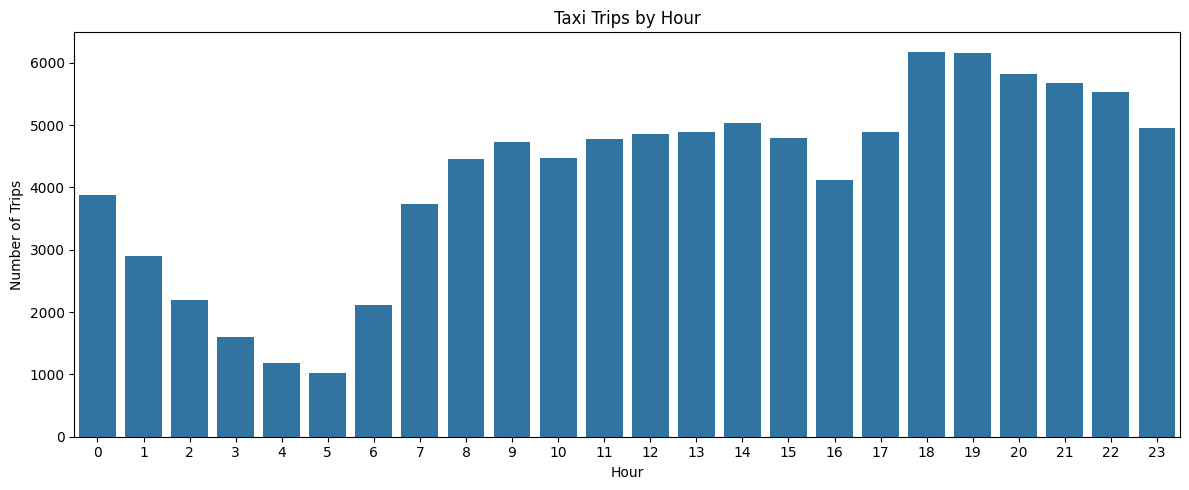

In [ ]:

# ============================================================
# 15. TRIPS BY HOUR
# ============================================================

hourly_trips = (

    df[
        "hour"
    ]
    .value_counts()
    .sort_index()
)


plt.figure(
    figsize=(12, 5)
)


sns.barplot(

    x=hourly_trips.index,

    y=hourly_trips.values
)


plt.title(
    "Taxi Trips by Hour"
)


plt.xlabel(
    "Hour"
)


plt.ylabel(
    "Number of Trips"
)


plt.tight_layout()

plt.show()

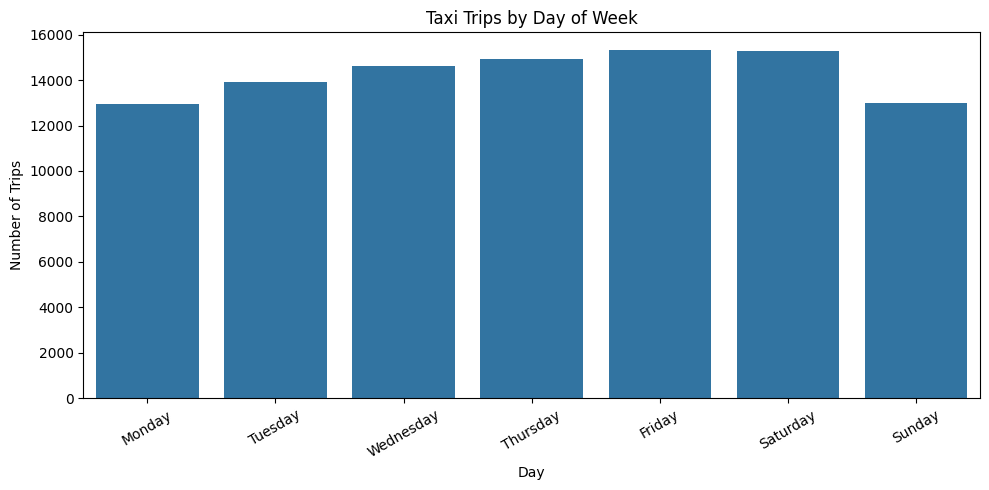

In [ ]:
# ============================================================
# 16. TRIPS BY DAY OF WEEK
# ============================================================

day_names = [

    "Monday",

    "Tuesday",

    "Wednesday",

    "Thursday",

    "Friday",

    "Saturday",

    "Sunday"
]


daily_trips = (

    df[
        "day_of_week"
    ]
    .value_counts()
    .sort_index()
)


plt.figure(
    figsize=(10, 5)
)


sns.barplot(

    x=[
        day_names[i]
        for i in daily_trips.index
    ],

    y=daily_trips.values
)


plt.title(
    "Taxi Trips by Day of Week"
)


plt.xlabel(
    "Day"
)


plt.ylabel(
    "Number of Trips"
)


plt.xticks(
    rotation=30
)


plt.tight_layout()

plt.show()


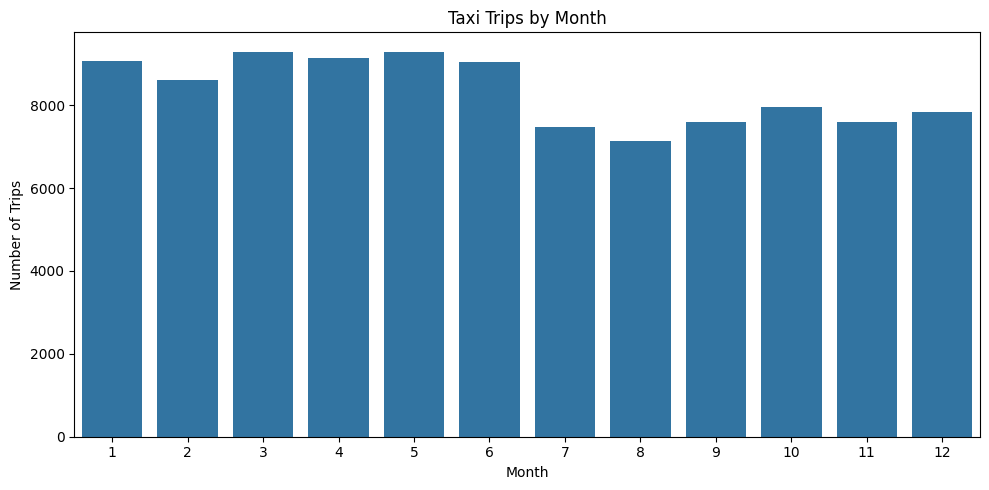

In [ ]:
# ============================================================
# 17. TRIPS BY MONTH
# ============================================================

monthly_trips = (

    df[
        "month"
    ]
    .value_counts()
    .sort_index()
)


plt.figure(
    figsize=(10, 5)
)


sns.barplot(

    x=monthly_trips.index,

    y=monthly_trips.values
)


plt.title(
    "Taxi Trips by Month"
)


plt.xlabel(
    "Month"
)


plt.ylabel(
    "Number of Trips"
)


plt.tight_layout()

plt.show()


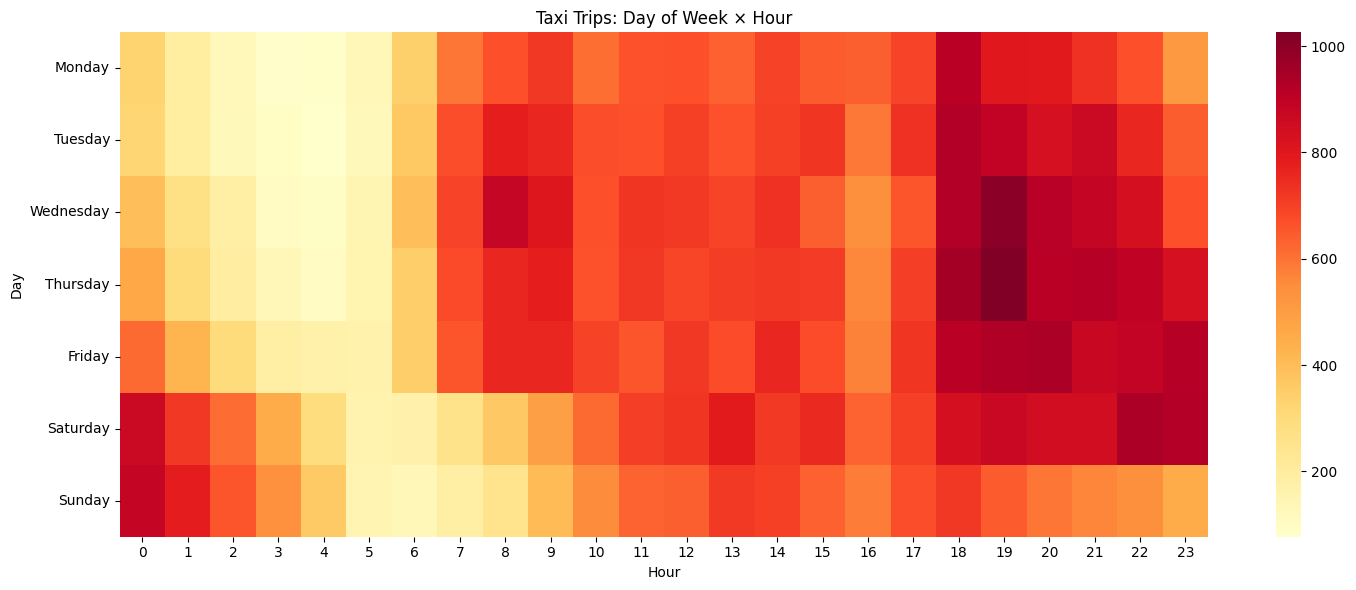

In [ ]:
# ============================================================
# 18. DAY × HOUR HEATMAP
# ============================================================

heatmap_data = pd.crosstab(

    df["day_of_week"],

    df["hour"]
)


heatmap_data.index = [

    day_names[i]

    for i in heatmap_data.index
]


plt.figure(
    figsize=(15, 6)
)


sns.heatmap(

    heatmap_data,

    cmap="YlOrRd"
)


plt.title(
    "Taxi Trips: Day of Week × Hour"
)


plt.xlabel(
    "Hour"
)


plt.ylabel(
    "Day"
)


plt.tight_layout()

plt.show()


GEOGRAPHIC ANALYSIS


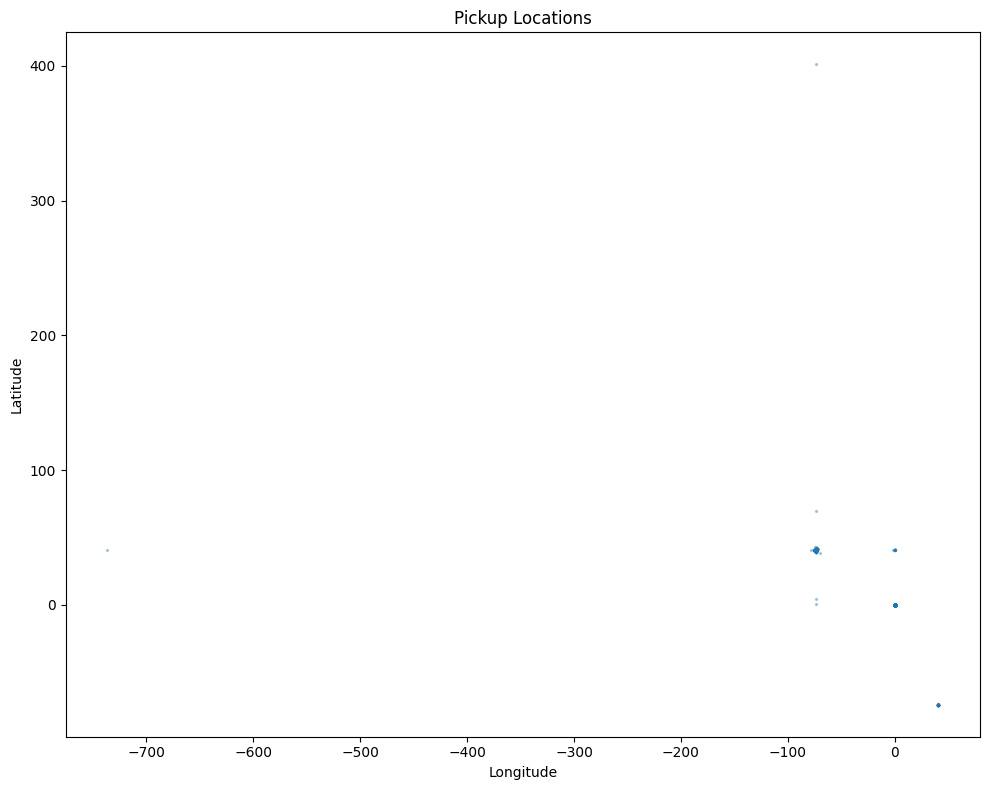

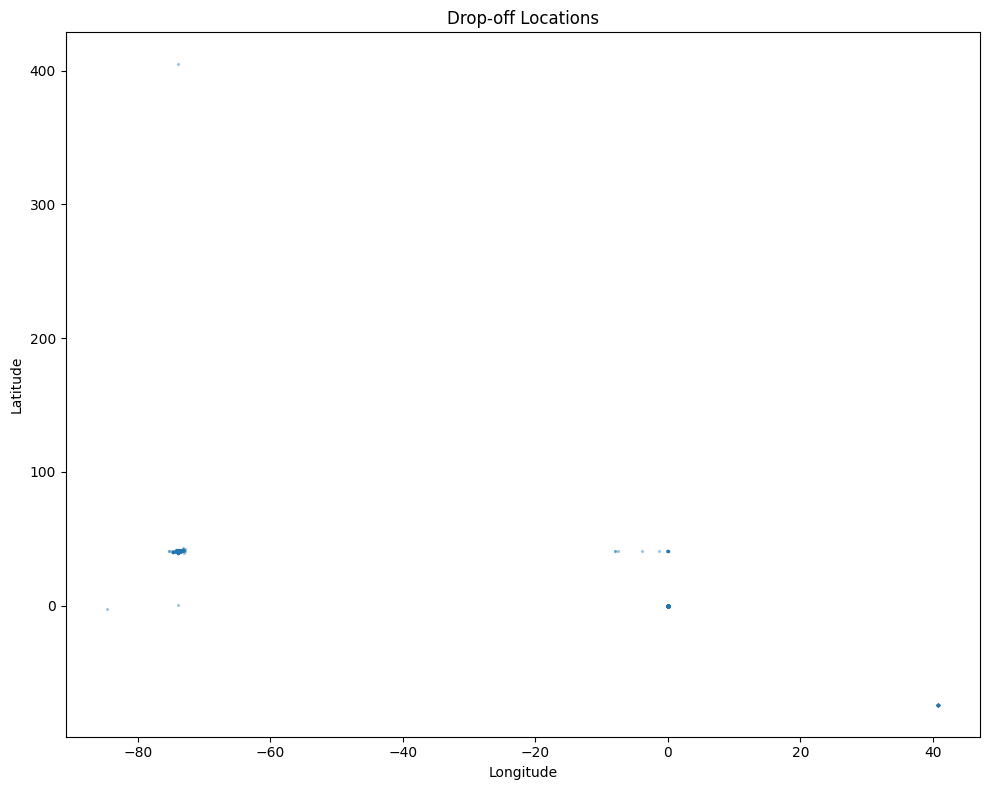

In [ ]:
# ============================================================
# 19. GEOGRAPHIC ANALYSIS
# ============================================================

print("\n" + "=" * 60)

print("GEOGRAPHIC ANALYSIS")

print("=" * 60)


# Pickup locations

plt.figure(
    figsize=(10, 8)
)


plt.scatter(

    df[
        "pickup_longitude"
    ],

    df[
        "pickup_latitude"
    ],

    s=2,

    alpha=0.3
)


plt.title(
    "Pickup Locations"
)


plt.xlabel(
    "Longitude"
)


plt.ylabel(
    "Latitude"
)


plt.tight_layout()

plt.show()


# Drop-off locations

plt.figure(
    figsize=(10, 8)
)


plt.scatter(

    df[
        "dropoff_longitude"
    ],

    df[
        "dropoff_latitude"
    ],

    s=2,

    alpha=0.3
)


plt.title(
    "Drop-off Locations"
)


plt.xlabel(
    "Longitude"
)


plt.ylabel(
    "Latitude"
)


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 20. GEOGRAPHIC DATA CLEANING
# ============================================================

print("\n" + "=" * 60)

print("GEOGRAPHIC DATA CLEANING")

print("=" * 60)


print(
    "Shape before geographic filtering:",
    df.shape
)


# Approximate NYC boundary

df = df[

    (
        df[
            "pickup_latitude"
        ]
        .between(40.4, 41.0)
    )

    &

    (
        df[
            "pickup_longitude"
        ]
        .between(-74.3, -73.5)
    )

    &

    (
        df[
            "dropoff_latitude"
        ]
        .between(40.4, 41.0)
    )

    &

    (
        df[
            "dropoff_longitude"
        ]
        .between(-74.3, -73.5)
    )
]


print(
    "Shape after geographic filtering:",
    df.shape
)



GEOGRAPHIC DATA CLEANING
Shape before geographic filtering: (100000, 15)
Shape after geographic filtering: (97796, 15)


In [ ]:
# ============================================================
# 21. PASSENGER COUNT CLEANING
# ============================================================

print("\n" + "=" * 60)

print("PASSENGER COUNT CLEANING")

print("=" * 60)


print(
    "Passenger counts:"
)


display(

    df[
        "passenger_count"
    ]
    .value_counts()
    .sort_index()
)


# Keep passenger counts 1–6

df = df[

    df[
        "passenger_count"
    ]
    .between(1, 6)
]


print(
    "Shape after passenger filtering:",
    df.shape
)


PASSENGER COUNT CLEANING
Passenger counts:


passenger_count
0      358
1    68038
2    14271
3     4210
4     2041
5     6874
6     2004
Name: count, dtype: int64

Shape after passenger filtering: (97438, 15)


In [ ]:
# ============================================================
# 22. FARE CLEANING
# ============================================================

print("\n" + "=" * 60)

print("FARE CLEANING")

print("=" * 60)


print(
    "Shape before fare filtering:",
    df.shape
)


# Remove zero and negative fares

df = df[

    df[
        "fare_amount"
    ]
    > 0
]


print(
    "After removing zero/negative fares:",
    df.shape
)


# 99th percentile

fare_upper_limit = (

    df[
        "fare_amount"
    ]
    .quantile(0.99)
)


print(
    "99th percentile fare:",
    fare_upper_limit
)


# Remove extreme fares

df = df[

    df[
        "fare_amount"
    ]
    <= fare_upper_limit
]


print(
    "After extreme fare filtering:",
    df.shape
)


FARE CLEANING
Shape before fare filtering: (97438, 15)
After removing zero/negative fares: (97427, 15)
99th percentile fare: 52.0
After extreme fare filtering: (96478, 15)


In [ ]:
# ============================================================
# 23. HAVERSINE DISTANCE FUNCTION
# ============================================================

def haversine_distance(

    lat1,

    lon1,

    lat2,

    lon2

):

    R = 6371.0


    lat1 = np.radians(
        lat1
    )

    lon1 = np.radians(
        lon1
    )


    lat2 = np.radians(
        lat2
    )

    lon2 = np.radians(
        lon2
    )


    dlat = (
        lat2 - lat1
    )

    dlon = (
        lon2 - lon1
    )


    a = (

        np.sin(
            dlat / 2
        ) ** 2

        +

        np.cos(lat1)

        *

        np.cos(lat2)

        *

        np.sin(
            dlon / 2
        ) ** 2
    )


    c = (

        2

        *

        np.arcsin(

            np.sqrt(a)
        )
    )


    return (
        R * c
    )


In [ ]:
# ============================================================
# 24. CALCULATE TRIP DISTANCE
# ============================================================

print("\n" + "=" * 60)

print("TRIP DISTANCE FEATURE ENGINEERING")

print("=" * 60)


df[
    "trip_distance_km"
] = haversine_distance(

    df[
        "pickup_latitude"
    ],

    df[
        "pickup_longitude"
    ],

    df[
        "dropoff_latitude"
    ],

    df[
        "dropoff_longitude"
    ]
)


display(

    df[
        "trip_distance_km"
    ].describe()
)



TRIP DISTANCE FEATURE ENGINEERING


count    96478.000000
mean         3.178025
std          3.221470
min          0.000000
25%          1.249995
50%          2.140029
75%          3.845370
max         39.221570
Name: trip_distance_km, dtype: float64

In [ ]:
# ============================================================
# 25. DISTANCE CLEANING
# ============================================================

print(
    "Shape before distance filtering:",
    df.shape
)


df = df[

    (
        df[
            "trip_distance_km"
        ]
        > 0
    )

    &

    (
        df[
            "trip_distance_km"
        ]
        < 100
    )
]


print(
    "Shape after distance filtering:",
    df.shape
)

Shape before distance filtering: (96478, 16)
Shape after distance filtering: (95461, 16)


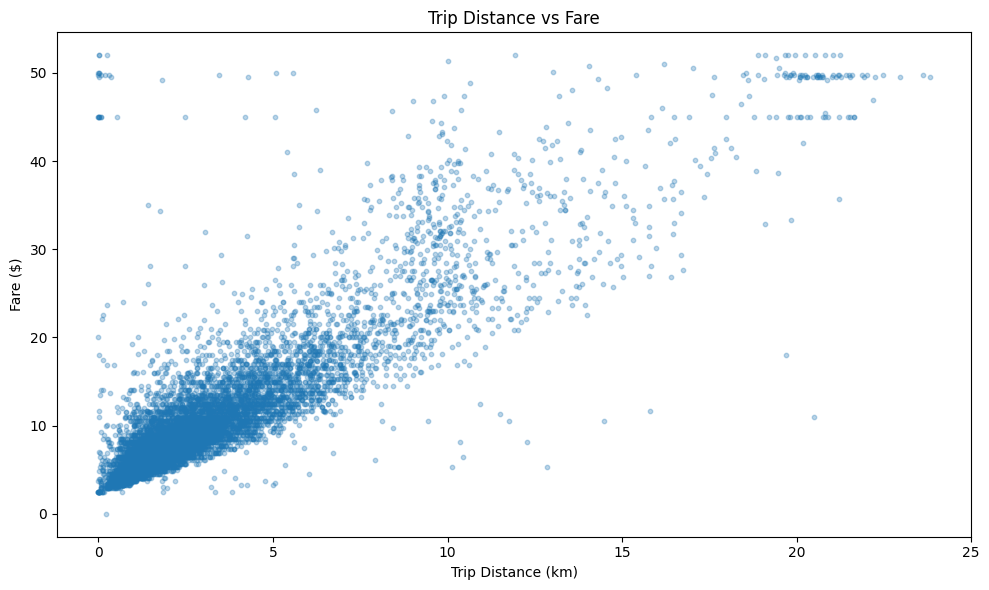

In [ ]:
# ============================================================
# 26. DISTANCE VS FARE
# ============================================================

sample_plot = df.sample(

    min(
        10000,
        len(df)
    ),

    random_state=SEED
)


plt.figure(
    figsize=(10, 6)
)


plt.scatter(

    sample_plot[
        "trip_distance_km"
    ],

    sample_plot[
        "fare_amount"
    ],

    alpha=0.3,

    s=10
)


plt.title(
    "Trip Distance vs Fare"
)


plt.xlabel(
    "Trip Distance (km)"
)


plt.ylabel(
    "Fare ($)"
)


plt.tight_layout()

plt.show()

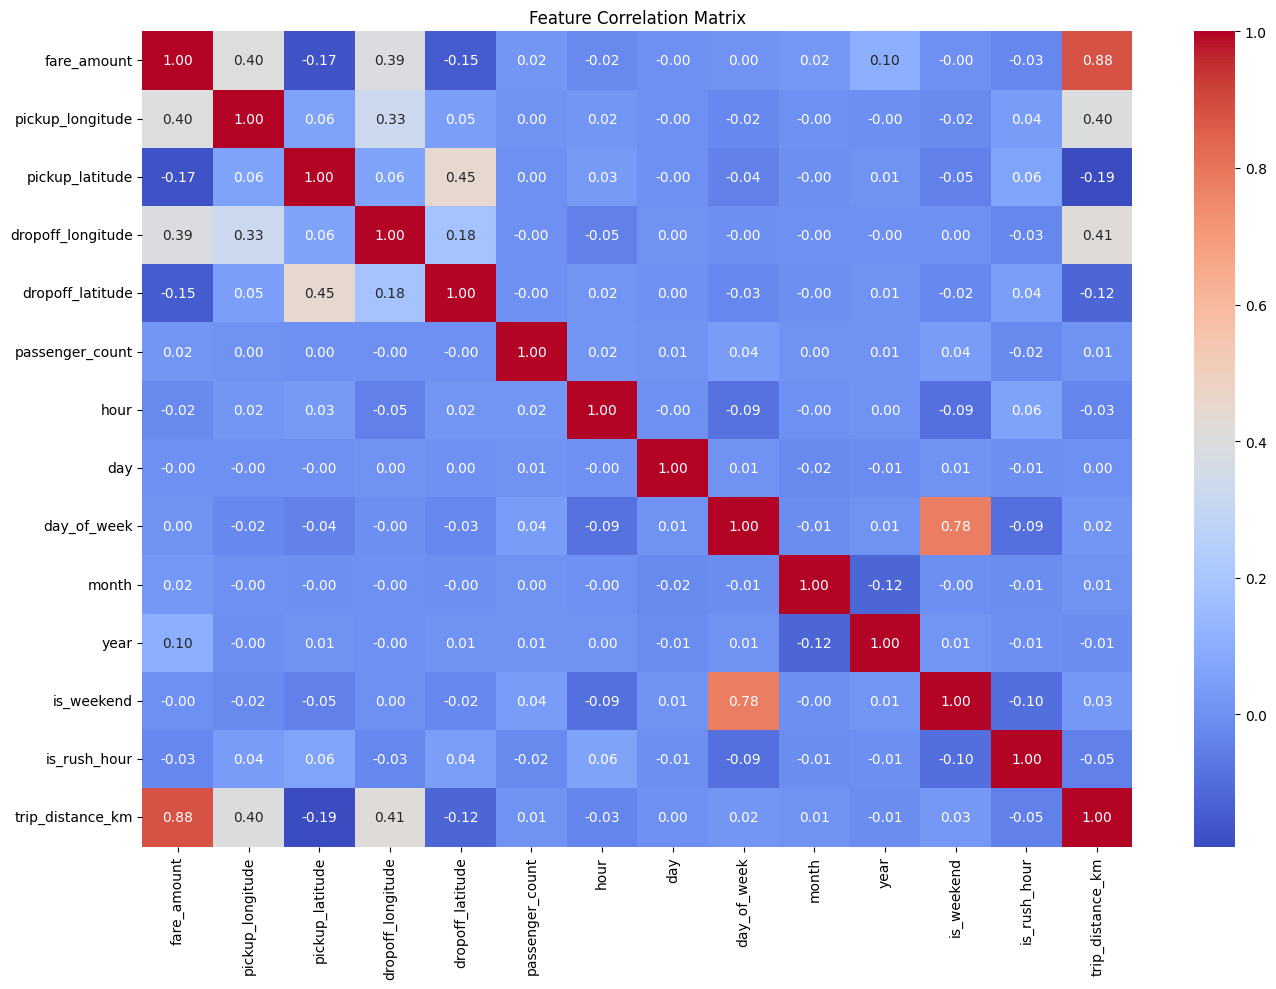

In [ ]:
# ============================================================
# 27. CORRELATION ANALYSIS
# ============================================================

numeric_cols = [

    "fare_amount",

    "pickup_longitude",

    "pickup_latitude",

    "dropoff_longitude",

    "dropoff_latitude",

    "passenger_count",

    "hour",

    "day",

    "day_of_week",

    "month",

    "year",

    "is_weekend",

    "is_rush_hour",

    "trip_distance_km"
]


correlation = (

    df[
        numeric_cols
    ]
    .corr()
)


plt.figure(
    figsize=(14, 10)
)


sns.heatmap(

    correlation,

    annot=True,

    fmt=".2f",

    cmap="coolwarm"
)


plt.title(
    "Feature Correlation Matrix"
)


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 28. FINAL FEATURES
# ============================================================

FEATURES = [

    "pickup_longitude",

    "pickup_latitude",

    "dropoff_longitude",

    "dropoff_latitude",

    "passenger_count",

    "hour",

    "day",

    "day_of_week",

    "month",

    "year",

    "is_weekend",

    "is_rush_hour",

    "trip_distance_km"
]


TARGET = "fare_amount"

In [ ]:
# ============================================================
# 29. CREATE X AND y
# ============================================================

X = df[
    FEATURES
].copy()


y = df[
    TARGET
].copy()


print(
    "Feature matrix shape:",
    X.shape
)


print(
    "Target shape:",
    y.shape
)


Feature matrix shape: (95461, 13)
Target shape: (95461,)


In [ ]:
# ============================================================
# 30. FINAL MISSING VALUE CHECK
# ============================================================

print("\nMissing values in X:")

print(
    X.isnull().sum()
)


print("\nMissing values in y:")

print(
    y.isnull().sum()
)


# Remove missing values

valid_indices = (

    X
    .dropna()
    .index
)


X = X.loc[
    valid_indices
]


y = y.loc[
    valid_indices
]


print(
    "\nFinal X shape:",
    X.shape
)


print(
    "Final y shape:",
    y.shape
)



Missing values in X:
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
day_of_week          0
month                0
year                 0
is_weekend           0
is_rush_hour         0
trip_distance_km     0
dtype: int64

Missing values in y:
0

Final X shape: (95461, 13)
Final y shape: (95461,)


In [ ]:
# ============================================================
# 31. TRAIN / VALIDATION / TEST SPLIT
# ============================================================
#
# 70% Training
# 15% Validation
# 15% Testing
# ============================================================

X_train, X_temp, y_train, y_temp = (

    train_test_split(

        X,

        y,

        test_size=0.30,

        random_state=SEED
    )
)


X_val, X_test, y_val, y_test = (

    train_test_split(

        X_temp,

        y_temp,

        test_size=0.50,

        random_state=SEED
    )
)


print("\n" + "=" * 60)

print("DATA SPLIT")

print("=" * 60)


print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_val.shape
)


print(
    "Testing:",
    X_test.shape
)



DATA SPLIT
Training: (66822, 13)
Validation: (14319, 13)
Testing: (14320, 13)


In [ ]:
# ============================================================
# 32. FEATURE SCALING
# ============================================================

scaler = StandardScaler()


# Fit ONLY on training data

X_train_scaled = (

    scaler.fit_transform(
        X_train
    )
)


X_val_scaled = (

    scaler.transform(
        X_val
    )
)


X_test_scaled = (

    scaler.transform(
        X_test
    )
)


print(
    "\nFeature scaling completed."
)


Feature scaling completed.


In [ ]:
# ============================================================
# 33. DNN MODEL FUNCTION
# ============================================================

def build_model(

    input_dim,

    learning_rate=0.001,

    dropout_rate=0.2

):

    model = Sequential([

        Dense(

            128,

            activation="relu",

            input_shape=(
                input_dim,
            )
        ),

        BatchNormalization(),

        Dropout(
            dropout_rate
        ),


        Dense(

            64,

            activation="relu"
        ),

        BatchNormalization(),

        Dropout(
            dropout_rate
        ),


        Dense(

            32,

            activation="relu"
        ),


        Dense(

            1,

            activation="linear"
        )
    ])


    optimizer = Adam(

        learning_rate=
            learning_rate
    )


    model.compile(

        optimizer=optimizer,

        loss=tf.keras.losses.Huber(),

        metrics=[

            tf.keras.metrics.MeanAbsoluteError(
                name="mae"
            ),

            tf.keras.metrics.RootMeanSquaredError(
                name="rmse"
            )
        ]
    )


    return model

In [ ]:
# ============================================================
# 34. CREATE INITIAL MODEL
# ============================================================

model = build_model(

    input_dim=
        X_train_scaled.shape[1],

    learning_rate=0.001,

    dropout_rate=0.2
)


print("\n" + "=" * 60)

print("MODEL SUMMARY")

print("=" * 60)


model.summary()


MODEL SUMMARY


2026-09-24 20:29:34.714420: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,545 (49.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ============================================================
# 35. CALLBACKS
# ============================================================

early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)


In [ ]:
# ============================================================
# 36. TRAIN INITIAL MODEL
# ============================================================

print("\n" + "=" * 60)

print("TRAINING INITIAL DNN")

print("=" * 60)


history = model.fit(

    X_train_scaled,

    y_train,

    validation_data=(

        X_val_scaled,

        y_val
    ),

    epochs=100,

    batch_size=128,

    callbacks=[

        early_stopping,

        reduce_lr
    ],

    verbose=1
)


TRAINING INITIAL DNN
Epoch 1/100
523/523 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 2.4770 - mae: 2.9233 - rmse: 4.9647 - val_loss: 1.4992 - val_mae: 1.9204 - val_rmse: 3.6337 - learning_rate: 0.0010
Epoch 2/100
523/523 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.7408 - mae: 2.1727 - rmse: 3.7296 - val_loss: 1.4436 - val_mae: 1.8581 - val_rmse: 3.5738 - learning_rate: 0.0010
Epoch 3/100
523/523 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.6439 - mae: 2.0720 - rmse: 3.6301 - val_loss: 1.3875 - val_mae: 1.7977 - val_rmse: 3.5164 - learning_rate: 0.0010
Epoch 4/100
523/523 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.5808 - mae: 2.0054 - rmse: 3.5449 - val_loss: 1.3431 - val_mae: 1.7467 - val_rmse: 3.4749 - learning_rate: 0.0010
Epoch 5/100
523/523 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.5460 - mae: 1.9695 - rmse: 3.5205 - val_loss: 1.3506 - val_mae: 1.7543 - val_rmse: 3.4729 - learning_rate: 0.0010
Epoch 6/100
523/523 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.5058 - mae: 1.9263 - rmse: 3.4

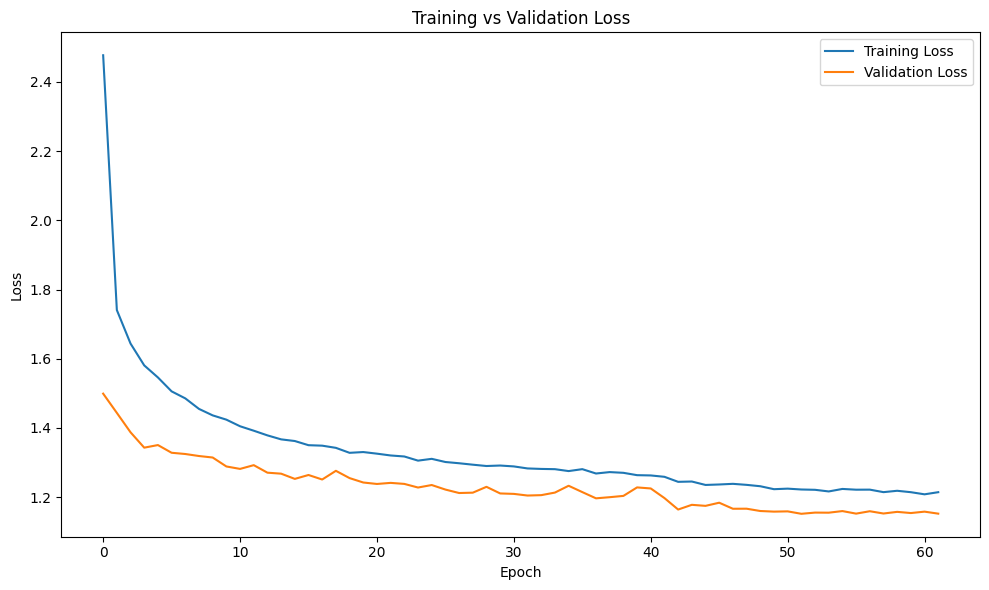

In [ ]:
# ============================================================
# 37. TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(

    history.history[
        "loss"
    ],

    label="Training Loss"
)


plt.plot(

    history.history[
        "val_loss"
    ],

    label="Validation Loss"
)


plt.title(
    "Training vs Validation Loss"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Loss"
)


plt.legend()


plt.tight_layout()

plt.show()

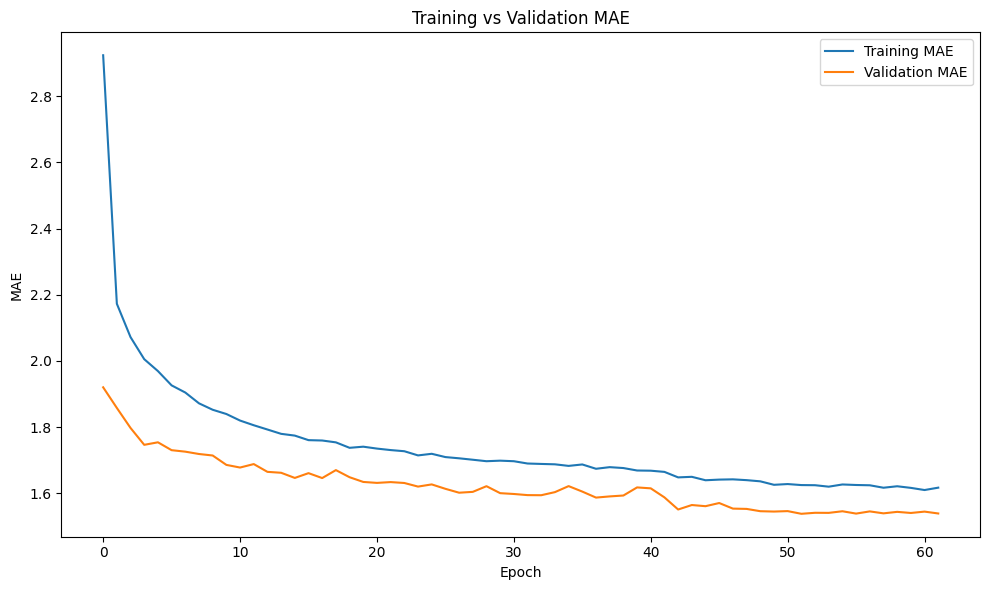

In [ ]:
# ============================================================
# 38. TRAINING VS VALIDATION MAE
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(

    history.history[
        "mae"
    ],

    label="Training MAE"
)


plt.plot(

    history.history[
        "val_mae"
    ],

    label="Validation MAE"
)


plt.title(
    "Training vs Validation MAE"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "MAE"
)


plt.legend()


plt.tight_layout()

plt.show()


In [ ]:
# ============================================================
# 39. INITIAL MODEL EVALUATION
# ============================================================

test_results = model.evaluate(

    X_test_scaled,

    y_test,

    verbose=0
)


print("\n" + "=" * 60)

print("INITIAL MODEL TEST RESULTS")

print("=" * 60)


print(
    "Test Loss:",
    test_results[0]
)


print(
    "Test MAE:",
    test_results[1]
)


print(
    "Test RMSE:",
    test_results[2]
)



INITIAL MODEL TEST RESULTS
Test Loss: 1.1774615049362183
Test MAE: 1.566021203994751
Test RMSE: 3.3754515647888184


In [ ]:
# ============================================================
# 40. INITIAL MODEL PREDICTIONS
# ============================================================

y_pred = (

    model.predict(

        X_test_scaled,

        verbose=0

    )
    .flatten()
)


In [ ]:
# ============================================================
# 41. INITIAL MODEL METRICS
# ============================================================

mae = (

    mean_absolute_error(

        y_test,

        y_pred
    )
)


mse = (

    mean_squared_error(

        y_test,

        y_pred
    )
)


rmse = np.sqrt(
    mse
)


r2 = (

    r2_score(

        y_test,

        y_pred
    )
)


print("\n" + "=" * 60)

print("INITIAL MODEL PERFORMANCE")

print("=" * 60)


print(
    f"MAE  : ${mae:.4f}"
)


print(
    f"MSE  : {mse:.4f}"
)


print(
    f"RMSE : ${rmse:.4f}"
)


print(
    f"R²   : {r2:.4f}"
)



INITIAL MODEL PERFORMANCE
MAE  : $1.5660
MSE  : 11.3937
RMSE : $3.3755
R²   : 0.8316


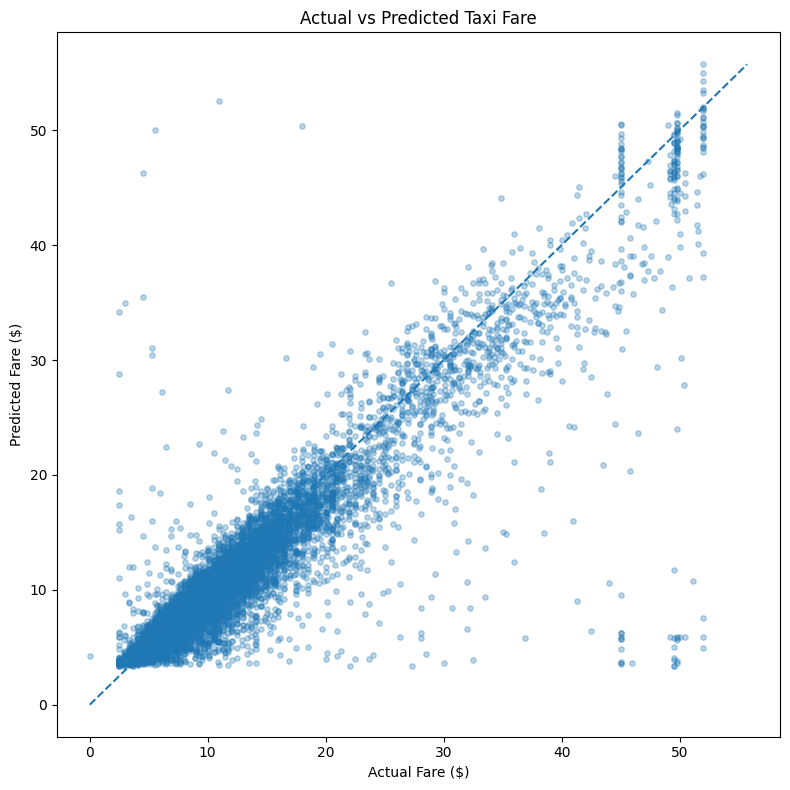

In [ ]:
# ============================================================
# 42. ACTUAL VS PREDICTED
# ============================================================

plt.figure(
    figsize=(8, 8)
)


plt.scatter(

    y_test,

    y_pred,

    alpha=0.3,

    s=15
)


min_value = min(

    y_test.min(),

    y_pred.min()
)


max_value = max(

    y_test.max(),

    y_pred.max()
)


plt.plot(

    [min_value, max_value],

    [min_value, max_value],

    linestyle="--"
)


plt.xlabel(
    "Actual Fare ($)"
)


plt.ylabel(
    "Predicted Fare ($)"
)


plt.title(
    "Actual vs Predicted Taxi Fare"
)


plt.tight_layout()

plt.show()

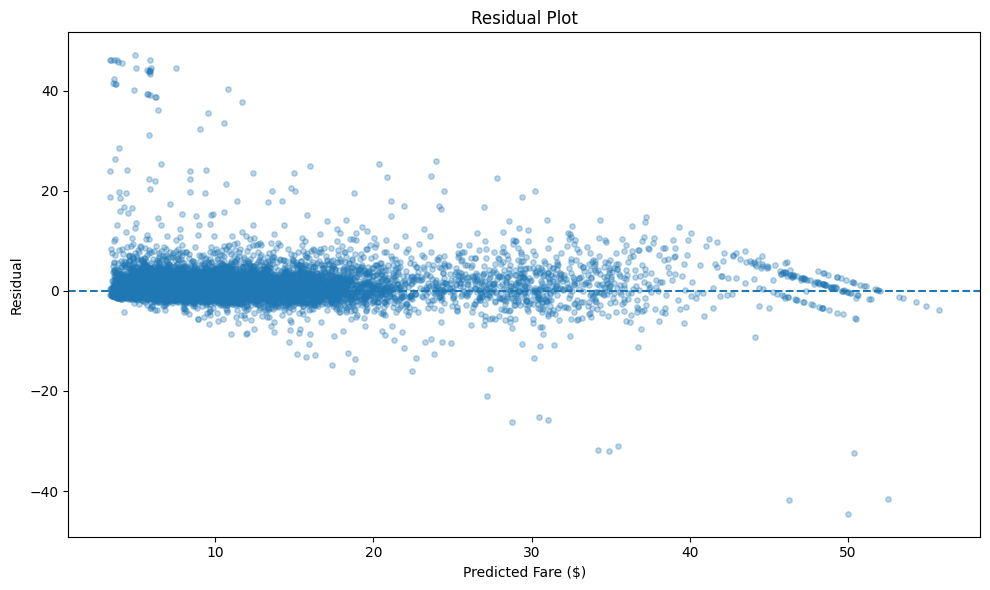

In [ ]:
# ============================================================
# 43. RESIDUAL ANALYSIS
# ============================================================

residuals = (

    y_test.values -

    y_pred
)


plt.figure(
    figsize=(10, 6)
)


plt.scatter(

    y_pred,

    residuals,

    alpha=0.3,

    s=15
)


plt.axhline(

    0,

    linestyle="--"
)


plt.xlabel(
    "Predicted Fare ($)"
)


plt.ylabel(
    "Residual"
)


plt.title(
    "Residual Plot"
)


plt.tight_layout()

plt.show()

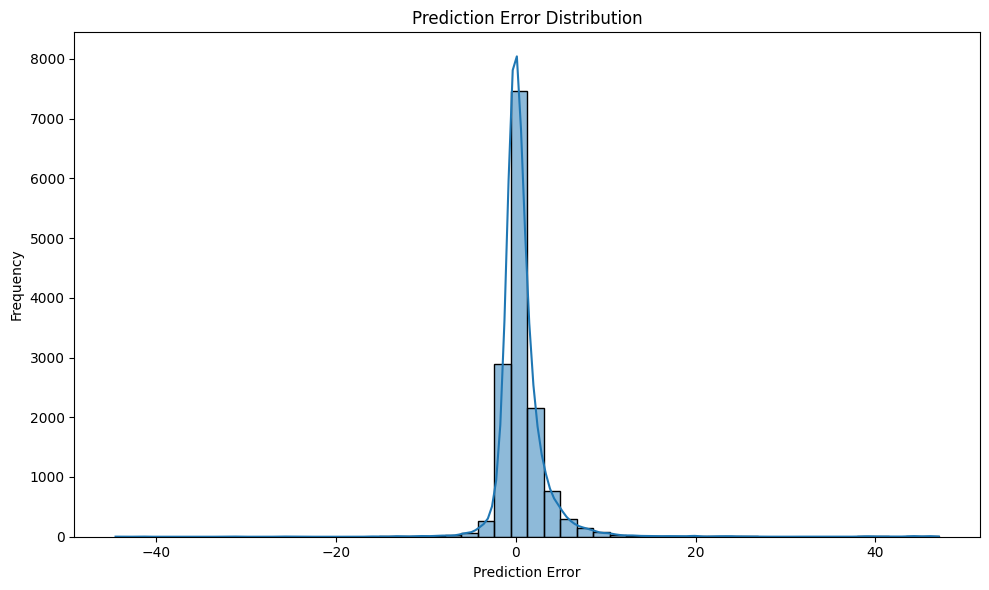

In [ ]:

# ============================================================
# 44. ERROR DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)


sns.histplot(

    residuals,

    bins=50,

    kde=True
)


plt.title(
    "Prediction Error Distribution"
)


plt.xlabel(
    "Prediction Error"
)


plt.ylabel(
    "Frequency"
)


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 45. LOSS FUNCTION COMPARISON
# ============================================================
#
# Compare:
# MSE
# MAE
# Huber
# ============================================================

def build_loss_model(

    loss_function

):

    model = Sequential([

        Dense(

            128,

            activation="relu",

            input_shape=(

                X_train_scaled.shape[1],

            )
        ),


        Dense(

            64,

            activation="relu"
        ),


        Dense(

            32,

            activation="relu"
        ),


        Dense(

            1,

            activation="linear"
        )
    ])


    model.compile(

        optimizer=Adam(

            learning_rate=0.001
        ),

        loss=loss_function,

        metrics=[

            "mae",

            tf.keras.metrics.RootMeanSquaredError(

                name="rmse"
            )
        ]
    )


    return model


In [ ]:

# ============================================================
# 46. MSE MODEL
# ============================================================

print(
    "\nTraining MSE model..."
)


mse_model = build_loss_model(
    "mse"
)


mse_history = mse_model.fit(

    X_train_scaled,

    y_train,

    validation_data=(

        X_val_scaled,

        y_val
    ),

    epochs=30,

    batch_size=128,

    verbose=0
)



Training MSE model...


In [ ]:
# ============================================================
# 47. MAE MODEL
# ============================================================

print(
    "Training MAE model..."
)


mae_model = build_loss_model(
    "mae"
)


mae_history = mae_model.fit(

    X_train_scaled,

    y_train,

    validation_data=(

        X_val_scaled,

        y_val
    ),

    epochs=30,

    batch_size=128,

    verbose=0
)

Training MAE model...


In [ ]:
# ============================================================
# 48. HUBER MODEL
# ============================================================

print(
    "Training Huber model..."
)


huber_model = build_loss_model(

    tf.keras.losses.Huber()
)


huber_history = huber_model.fit(

    X_train_scaled,

    y_train,

    validation_data=(

        X_val_scaled,

        y_val
    ),

    epochs=30,

    batch_size=128,

    verbose=0
)

Training Huber model...


In [ ]:
# ============================================================
# 49. LOSS FUNCTION RESULTS
# ============================================================

print("\n" + "=" * 60)

print("LOSS FUNCTION COMPARISON")

print("=" * 60)


print(

    "MSE final validation loss:",

    mse_history.history[
        "val_loss"
    ][-1]
)


print(

    "MAE final validation loss:",

    mae_history.history[
        "val_loss"
    ][-1]
)


print(

    "Huber final validation loss:",

    huber_history.history[
        "val_loss"
    ][-1]
)



LOSS FUNCTION COMPARISON
MSE final validation loss: 10.300731658935547
MAE final validation loss: 1.5554269552230835
Huber final validation loss: 1.1484986543655396


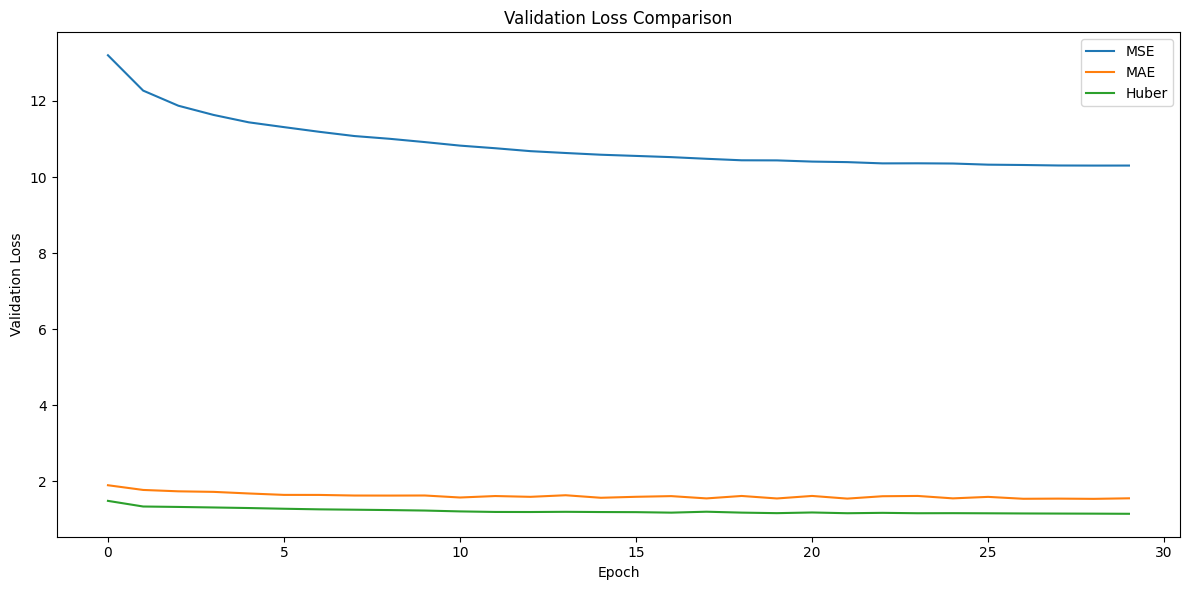

In [ ]:
# ============================================================
# 50. LOSS COMPARISON GRAPH
# ============================================================

plt.figure(
    figsize=(12, 6)
)


plt.plot(

    mse_history.history[
        "val_loss"
    ],

    label="MSE"
)


plt.plot(

    mae_history.history[
        "val_loss"
    ],

    label="MAE"
)


plt.plot(

    huber_history.history[
        "val_loss"
    ],

    label="Huber"
)


plt.title(
    "Validation Loss Comparison"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Validation Loss"
)


plt.legend()


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 51. HYPERPARAMETER EXPERIMENTS
# ============================================================

experiments = [

    {

        "name": "Model_1",

        "neurons": [

            128,

            64,

            32
        ],

        "dropout": 0.0,

        "lr": 0.001
    },


    {

        "name": "Model_2",

        "neurons": [

            128,

            64,

            32
        ],

        "dropout": 0.2,

        "lr": 0.001
    },


    {

        "name": "Model_3",

        "neurons": [

            256,

            128,

            64
        ],

        "dropout": 0.2,

        "lr": 0.001
    },


    {

        "name": "Model_4",

        "neurons": [

            128,

            64,

            32
        ],

        "dropout": 0.3,

        "lr": 0.0005
    }
]

In [ ]:
# ============================================================
# 52. HYPERPARAMETER MODEL BUILDER
# ============================================================

def build_tuning_model(

    input_dim,

    neurons,

    dropout,

    lr

):

    model = Sequential()


    # First hidden layer

    model.add(

        Dense(

            neurons[0],

            activation="relu",

            input_shape=(

                input_dim,

            )
        )
    )


    # Remaining hidden layers

    for units in neurons[1:]:

        model.add(

            Dense(

                units,

                activation="relu"
            )
        )


        if dropout > 0:

            model.add(

                Dropout(

                    dropout
                )
            )


    # Output layer

    model.add(

        Dense(

            1,

            activation="linear"
        )
    )


    model.compile(

        optimizer=Adam(

            learning_rate=lr
        ),

        loss=tf.keras.losses.Huber(),

        metrics=[

            "mae",

            tf.keras.metrics.RootMeanSquaredError(

                name="rmse"
            )
        ]
    )


    return model

In [ ]:
# ============================================================
# 53. RUN HYPERPARAMETER EXPERIMENTS
# ============================================================

results = []


best_model = None


best_model_name = None


best_val_loss = float(
    "inf"
)


for exp in experiments:

    print(
        "\nTraining:",
        exp["name"]
    )


    temp_model = build_tuning_model(

        input_dim=
            X_train_scaled.shape[1],

        neurons=
            exp["neurons"],

        dropout=
            exp["dropout"],

        lr=
            exp["lr"]
    )


    temp_history = temp_model.fit(

        X_train_scaled,

        y_train,

        validation_data=(

            X_val_scaled,

            y_val
        ),

        epochs=40,

        batch_size=128,

        callbacks=[

            EarlyStopping(

                monitor="val_loss",

                patience=5,

                restore_best_weights=True
            )
        ],

        verbose=0
    )


    # Best validation loss

    current_best_val_loss = min(

        temp_history.history[
            "val_loss"
        ]
    )


    # Test prediction

    predictions = (

        temp_model.predict(

            X_test_scaled,

            verbose=0

        )
        .flatten()
    )


    # Metrics

    temp_mae = (

        mean_absolute_error(

            y_test,

            predictions
        )
    )


    temp_mse = (

        mean_squared_error(

            y_test,

            predictions
        )
    )


    temp_rmse = np.sqrt(
        temp_mse
    )


    temp_r2 = (

        r2_score(

            y_test,

            predictions
        )
    )


    # Store result

    results.append({

        "Model":
            exp["name"],

        "Neurons":
            str(exp["neurons"]),

        "Dropout":
            exp["dropout"],

        "Learning Rate":
            exp["lr"],

        "MAE":
            temp_mae,

        "MSE":
            temp_mse,

        "RMSE":
            temp_rmse,

        "R2":
            temp_r2,

        "Best Validation Loss":
            current_best_val_loss
    })


    # Automatically select model
    # with lowest validation loss

    if (

        current_best_val_loss

        <

        best_val_loss

    ):

        best_val_loss = (

            current_best_val_loss
        )


        best_model = (
            temp_model
        )


        best_model_name = (

            exp["name"]
        )


    gc.collect()



Training: Model_1

Training: Model_2

Training: Model_3

Training: Model_4


In [ ]:
# ============================================================
# 54. MODEL COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(
    results
)


print("\n" + "=" * 60)

print(
    "HYPERPARAMETER TUNING RESULTS"
)

print("=" * 60)


display(
    results_df
)



HYPERPARAMETER TUNING RESULTS


,Model,Neurons,Dropout,Learning Rate,MAE,MSE,RMSE,R2,Best Validation Loss
0,Model_1,"[128, 64, 32]",0.0,0.0010,1.545212,10.765375,3.281063,0.840894,1.145186
1,Model_2,"[128, 64, 32]",0.2,0.0010,1.581036,10.900159,3.301539,0.838902,1.160982
2,Model_3,"[256, 128, 64]",0.2,0.0010,1.546493,10.865208,3.296241,0.839419,1.128796
3,Model_4,"[128, 64, 32]",0.3,0.0005,1.639687,11.252792,3.354518,0.833690,1.216951


In [ ]:
# ============================================================
# 55. SAVE MODEL COMPARISON
# ============================================================

results_df.to_csv(

    "model_comparison.csv",

    index=False
)

In [ ]:
# ============================================================
# 56. BEST MODEL
# ============================================================

print("\n" + "=" * 60)

print("BEST MODEL")

print("=" * 60)


print(
    "Best Model:",
    best_model_name
)


print(
    "Best Validation Loss:",
    best_val_loss
)


BEST MODEL
Best Model: Model_3
Best Validation Loss: 1.128795862197876


In [ ]:
# ============================================================
# 57. FINAL MODEL
# ============================================================

final_model = (
    best_model
)


In [ ]:
# ============================================================
# 58. FINAL PREDICTIONS
# ============================================================

final_pred = (

    final_model.predict(

        X_test_scaled,

        verbose=0

    )
    .flatten()
)


In [ ]:
# ============================================================
# 59. FINAL MODEL METRICS
# ============================================================

final_mae = (

    mean_absolute_error(

        y_test,

        final_pred
    )
)


final_mse = (

    mean_squared_error(

        y_test,

        final_pred
    )
)


final_rmse = np.sqrt(
    final_mse
)


final_r2 = (

    r2_score(

        y_test,

        final_pred
    )
)


print("\n" + "=" * 60)

print("FINAL MODEL PERFORMANCE")

print("=" * 60)


print(
    f"MAE  : ${final_mae:.4f}"
)


print(
    f"MSE  : {final_mse:.4f}"
)


print(
    f"RMSE : ${final_rmse:.4f}"
)


print(
    f"R²   : {final_r2:.4f}"
)



FINAL MODEL PERFORMANCE
MAE  : $1.5465
MSE  : 10.8652
RMSE : $3.2962
R²   : 0.8394


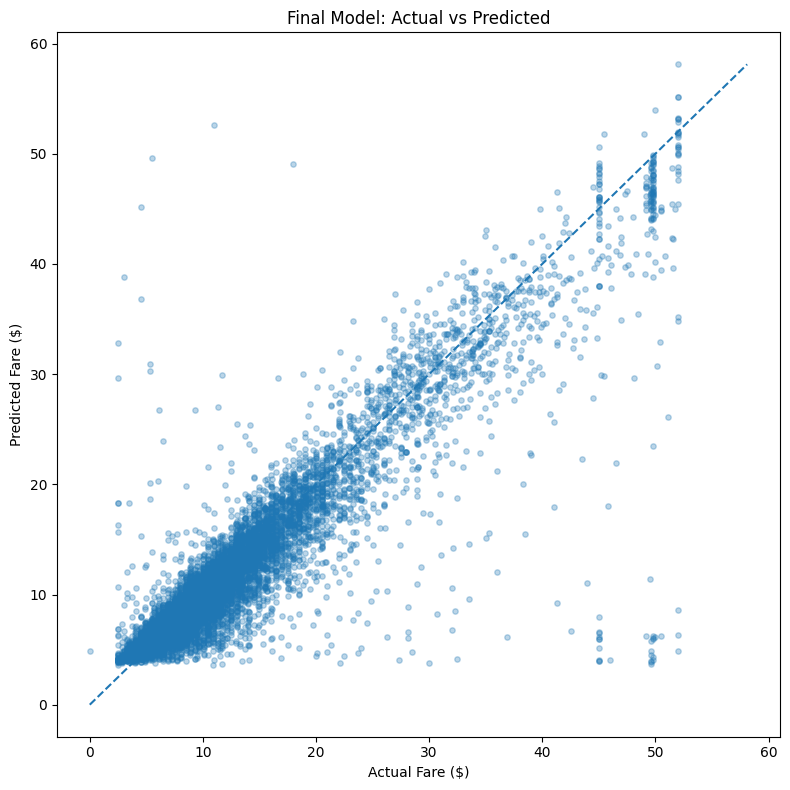

In [ ]:
# ============================================================
# 60. FINAL ACTUAL VS PREDICTED
# ============================================================

plt.figure(
    figsize=(8, 8)
)


plt.scatter(

    y_test,

    final_pred,

    alpha=0.3,

    s=15
)


min_val = min(

    y_test.min(),

    final_pred.min()
)


max_val = max(

    y_test.max(),

    final_pred.max()
)


plt.plot(

    [min_val, max_val],

    [min_val, max_val],

    linestyle="--"
)


plt.xlabel(
    "Actual Fare ($)"
)


plt.ylabel(
    "Predicted Fare ($)"
)


plt.title(
    "Final Model: Actual vs Predicted"
)


plt.tight_layout()

plt.show()

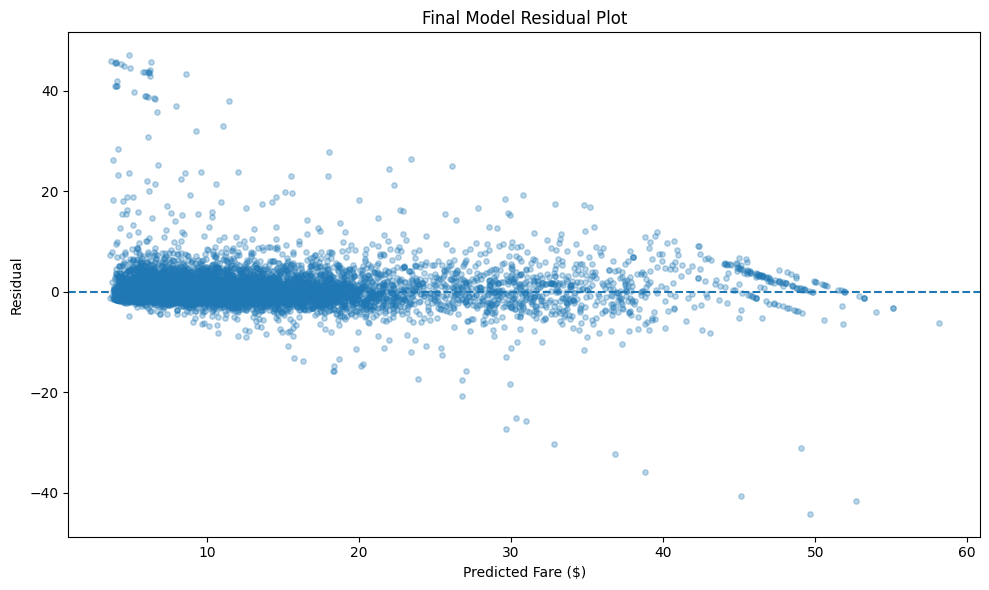

In [ ]:
# ============================================================
# 61. FINAL RESIDUAL PLOT
# ============================================================

final_residuals = (

    y_test.values -

    final_pred
)


plt.figure(
    figsize=(10, 6)
)


plt.scatter(

    final_pred,

    final_residuals,

    alpha=0.3,

    s=15
)


plt.axhline(

    0,

    linestyle="--"
)


plt.xlabel(
    "Predicted Fare ($)"
)


plt.ylabel(
    "Residual"
)


plt.title(
    "Final Model Residual Plot"
)


plt.tight_layout()

plt.show()

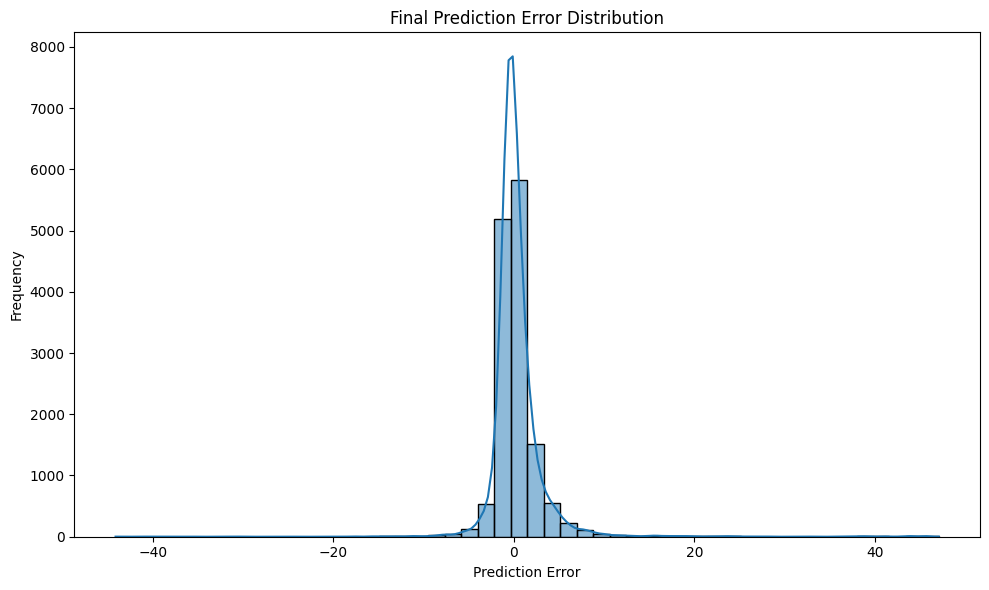

In [ ]:
# ============================================================
# 62. FINAL ERROR DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)


sns.histplot(

    final_residuals,

    bins=50,

    kde=True
)


plt.title(
    "Final Prediction Error Distribution"
)


plt.xlabel(
    "Prediction Error"
)


plt.ylabel(
    "Frequency"
)


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 63. SAVE FINAL MODEL
# ============================================================

final_model.save(

    "nyc_taxi_fare_model.keras"
)


# Save scaler

joblib.dump(

    scaler,

    "taxi_scaler.pkl"
)


# Save feature names

joblib.dump(

    FEATURES,

    "taxi_features.pkl"
)


print("\n" + "=" * 60)

print("MODEL SAVING")

print("=" * 60)


print(
    "Saved: nyc_taxi_fare_model.keras"
)


print(
    "Saved: taxi_scaler.pkl"
)


print(
    "Saved: taxi_features.pkl"
)



MODEL SAVING
Saved: nyc_taxi_fare_model.keras
Saved: taxi_scaler.pkl
Saved: taxi_features.pkl


In [ ]:
# ============================================================
# 64. FINAL RESULTS TABLE
# ============================================================

final_results = pd.DataFrame({

    "Metric": [

        "MAE",

        "MSE",

        "RMSE",

        "R2"
    ],

    "Value": [

        final_mae,

        final_mse,

        final_rmse,

        final_r2
    ]
})


print("\n" + "=" * 60)

print("FINAL RESULTS TABLE")

print("=" * 60)


display(
    final_results
)


# Save results

final_results.to_csv(

    "final_model_results.csv",

    index=False
)



FINAL RESULTS TABLE


,Metric,Value
0,MAE,1.546493
1,MSE,10.865208
2,RMSE,3.296241
3,R2,0.839419


In [ ]:
# ============================================================
# 65. PREDICTION FUNCTION
# ============================================================

def predict_fare(

    pickup_latitude,

    pickup_longitude,

    dropoff_latitude,

    dropoff_longitude,

    pickup_datetime,

    passenger_count

):

    # Convert datetime

    pickup_datetime = pd.to_datetime(

        pickup_datetime
    )


    # Temporal features

    hour = (
        pickup_datetime.hour
    )


    day = (
        pickup_datetime.day
    )


    day_of_week = (
        pickup_datetime.dayofweek
    )


    month = (
        pickup_datetime.month
    )


    year = (
        pickup_datetime.year
    )


    # Weekend

    is_weekend = int(

        day_of_week >= 5
    )


    # Rush hour

    is_rush_hour = int(

        (

            (
                hour >= 7
            )

            &

            (
                hour <= 9
            )

        )

        |

        (

            (
                hour >= 16
            )

            &

            (
                hour <= 19
            )

        )
    )


    # Distance

    distance = haversine_distance(

        pickup_latitude,

        pickup_longitude,

        dropoff_latitude,

        dropoff_longitude
    )


    # Create DataFrame

    input_data = pd.DataFrame(

        [[

            pickup_longitude,

            pickup_latitude,

            dropoff_longitude,

            dropoff_latitude,

            passenger_count,

            hour,

            day,

            day_of_week,

            month,

            year,

            is_weekend,

            is_rush_hour,

            distance

        ]],

        columns=FEATURES
    )


    # Scale input

    input_scaled = (

        scaler.transform(

            input_data
        )
    )


    # Predict

    prediction = (

        final_model.predict(

            input_scaled,

            verbose=0

        )[0][0]
    )


    return prediction

In [ ]:
# ============================================================
# 66. TEST PREDICTION FUNCTION
# ============================================================

print("\n" + "=" * 60)

print("TESTING PREDICTION FUNCTION")

print("=" * 60)


test_fare = predict_fare(

    pickup_latitude=40.7580,

    pickup_longitude=-73.9855,

    dropoff_latitude=40.7484,

    dropoff_longitude=-73.9857,

    pickup_datetime=
        "2026-09-23 18:30:00",

    passenger_count=2
)


print(

    f"Estimated Taxi Fare: "
    f"${test_fare:.2f}"
)


TESTING PREDICTION FUNCTION
Estimated Taxi Fare: $11.96


In [ ]:
# ============================================================
# 68. FINAL OUTPUT FILES
# ============================================================

print("\n" + "=" * 60)

print("PROJECT COMPLETE")

print("=" * 60)


print(
    "\nGenerated files:"
)


print(
    "1. nyc_taxi_fare_model.keras"
)


print(
    "2. taxi_scaler.pkl"
)


print(
    "3. taxi_features.pkl"
)


print(
    "4. model_comparison.csv"
)


print(
    "5. final_model_results.csv"
)


print("\nFinal metrics:")

print(
    f"MAE  = ${final_mae:.4f}"
)

print(
    f"MSE  = {final_mse:.4f}"
)

print(
    f"RMSE = ${final_rmse:.4f}"
)

print(
    f"R²   = {final_r2:.4f}"
)


PROJECT COMPLETE

Generated files:
1. nyc_taxi_fare_model.keras
2. taxi_scaler.pkl
3. taxi_features.pkl
4. model_comparison.csv
5. final_model_results.csv

Final metrics:
MAE  = $1.5465
MSE  = 10.8652
RMSE = $3.2962
R²   = 0.8394


In [ ]:
# ============================================================
# INSTALL GRADIO FRPC
# ============================================================

import os
import urllib.request

frpc_dir = "/root/.cache/huggingface/gradio/frpc"

frpc_file = os.path.join(
    frpc_dir,
    "frpc_linux_amd64_v0.3"
)

os.makedirs(
    frpc_dir,
    exist_ok=True
)

frpc_url = (
    "https://cdn-media.huggingface.co/"
    "frpc-gradio-0.3/frpc_linux_amd64"
)

print("Downloading FRPC...")

try:

    urllib.request.urlretrieve(
        frpc_url,
        frpc_file
    )

    os.chmod(
        frpc_file,
        0o755
    )

    print("\nFRPC downloaded successfully.")

    print(
        "Location:",
        frpc_file
    )

except Exception as e:

    print("\nFRPC download failed.")
    print("Error:", e)


FRPC downloaded successfully.
Location: /root/.cache/huggingface/gradio/frpc/frpc_linux_amd64_v0.3


In [ ]:
print("predict_fare exists:", "predict_fare" in globals())

predict_fare exists: True


In [ ]:
# ============================================================
# 67. OPTIONAL GRADIO DEPLOYMENT
# ============================================================

try:

    import gradio as gr


    def gradio_prediction(

        pickup_lat,

        pickup_lon,

        dropoff_lat,

        dropoff_lon,

        date,

        time,

        passengers

    ):

        try:

            datetime_string = (

                f"{date} {time}"
            )


            fare = predict_fare(

                pickup_latitude=
                    float(
                        pickup_lat
                    ),

                pickup_longitude=
                    float(
                        pickup_lon
                    ),

                dropoff_latitude=
                    float(
                        dropoff_lat
                    ),

                dropoff_longitude=
                    float(
                        dropoff_lon
                    ),

                pickup_datetime=
                    datetime_string,

                passenger_count=
                    int(
                        passengers
                    )
            )


            return (

                f"Estimated Taxi Fare: "
                f"${fare:.2f}"
            )


        except Exception as e:

            return (
                f"Error: {str(e)}"
            )


    demo = gr.Interface(

        fn=gradio_prediction,

        inputs=[

            gr.Number(

                label=
                    "Pickup Latitude",

                value=40.7580
            ),

            gr.Number(

                label=
                    "Pickup Longitude",

                value=-73.9855
            ),

            gr.Number(

                label=
                    "Drop-off Latitude",

                value=40.7484
            ),

            gr.Number(

                label=
                    "Drop-off Longitude",

                value=-73.9857
            ),

            gr.Textbox(

                label="Date",

                value="2026-09-23"
            ),

            gr.Textbox(

                label="Time",

                value="18:30"
            ),

            gr.Number(

                label=
                    "Passenger Count",

                value=2
            )
        ],


        outputs=gr.Textbox(

            label=
                "Estimated Taxi Fare"
        ),


        title=
            "NYC Taxi Fare Prediction",


        description=(

            "Enter taxi trip details "
            "to estimate taxi fare."
        )
    )


    print("\n" + "=" * 60)

    print(
        "LAUNCHING GRADIO DEPLOYMENT"
    )

    print("=" * 60)


    demo.launch(
        share=True,
        debug=True
    )


except Exception as e:

    print("\nGradio deployment skipped.")

    print(
        "Reason:",
        str(e)
    )


LAUNCHING GRADIO DEPLOYMENT
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://dca5217cba493a24d5.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
